In [16]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [5]:
data = 'toy_spread_funding_two_products.csv'
df = pd.read_csv(data).set_index('timestamp_utc')
df.index = pd.to_datetime(df.index)
df.head()

,product,spot_symbol,perp_symbol,spot_quote_ccy,perp_quote_ccy,spot_qty,perp_qty,spot_bid,spot_ask,perp_bid,perp_ask,perp_mark_price,index_price,usdc_usdt,funding_rate_8h,funding_event,spot_volume_usd,perp_volume_usd,open_interest_usd
timestamp_utc,,,,,,,,,,,,,,,,,,,
2026-09-15 00:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79996.80,80003.20,80125.26,80138.09,80113.00,80007.17,1.000090,0.000042,0,8.058144e+07,2.109624e+08,1.791965e+09
2026-09-15 00:00:00+00:00,ETH,ETH-USDT,ETH-USDT-PERP,USDT,USDT,10.0,-10.0,3199.59,3200.41,3202.18,3202.69,3202.14,3200.00,1.000000,0.000028,0,3.551676e+07,1.824232e+08,8.891708e+08
2026-09-15 01:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79843.37,79857.39,80004.49,80017.09,79989.72,79870.32,1.000250,0.000051,0,9.720665e+07,1.224543e+08,1.796887e+09
2026-09-15 01:00:00+00:00,ETH,ETH-USDT,ETH-USDT-PERP,USDT,USDT,10.0,-10.0,3196.13,3196.87,3200.53,3200.95,3200.23,3196.50,1.000000,0.000033,0,5.319370e+07,1.598502e+08,9.016021e+08
2026-09-15 02:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79945.97,79970.67,80112.17,80121.18,80095.28,79974.08,1.000197,0.000039,0,1.206133e+08,2.960957e+08,1.797561e+09


In [6]:
df_btc = df[df['product'] == 'BTC']
df_btc.head()

,product,spot_symbol,perp_symbol,spot_quote_ccy,perp_quote_ccy,spot_qty,perp_qty,spot_bid,spot_ask,perp_bid,perp_ask,perp_mark_price,index_price,usdc_usdt,funding_rate_8h,funding_event,spot_volume_usd,perp_volume_usd,open_interest_usd
timestamp_utc,,,,,,,,,,,,,,,,,,,
2026-09-15 00:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79996.80,80003.20,80125.26,80138.09,80113.00,80007.17,1.000090,0.000042,0,8.058144e+07,2.109624e+08,1.791965e+09
2026-09-15 01:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79843.37,79857.39,80004.49,80017.09,79989.72,79870.32,1.000250,0.000051,0,9.720665e+07,1.224543e+08,1.796887e+09
2026-09-15 02:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79945.97,79970.67,80112.17,80121.18,80095.28,79974.08,1.000197,0.000039,0,1.206133e+08,2.960957e+08,1.797561e+09
2026-09-15 03:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,80085.01,80102.60,80269.65,80280.16,80250.78,80114.06,1.000253,0.000038,0,5.868380e+07,1.812772e+08,1.804674e+09
2026-09-15 04:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79806.04,79819.99,80015.51,80019.51,79988.14,79821.70,1.000109,0.000046,0,8.136117e+07,1.854489e+08,1.824991e+09


#### Question 1: Mid price calculations for both Spot and Perp. Then, raw spread calculation and basis in bps.

Calculate the spot and perp mid-prices from bid/ask. Then calculate the raw spread

$$ \text{Basis}_t=P^{perp}_t-P^{spot}_t $$

and basis in bps. For BTC, remember the spot is quoted in USDC, so decide how you need to use usdc_usdt before comparing it with the USDT perp.

In [8]:
df_btc['Spot_Mid'] = (df_btc['spot_ask'] + df_btc['spot_bid']) / 2
df_btc['Perp_Mid'] = (df_btc['perp_ask'] + df_btc['perp_bid']) / 2
df_btc['Spot_Mid_USDT_Terms'] = df_btc['Spot_Mid'] * df_btc['usdc_usdt'] # Since Spot is in USDC terms, we need to see how much it would be worth in terms of USDT, so we multiply. 
df_btc['Perp_Mid_USDC_Terms'] = df_btc['Perp_Mid'] / df_btc['usdc_usdt'] # Logic above, but vice versa
df_btc['USDT_Basis'] = df_btc['Perp_Mid'] - df_btc['Spot_Mid_USDT_Terms']
df_btc['USDC_Basis'] = df_btc['Perp_Mid_USDC_Terms'] - df_btc['Spot_Mid']
df_btc['BasisInBPS_USDT'] = (df_btc['USDT_Basis'] / ((df_btc['Spot_Mid'] + df_btc['Perp_Mid']) / 2) ) * 10_000
df_btc['BasisInBPS_USDC'] = (df_btc['USDC_Basis'] / ((df_btc['Spot_Mid'] + df_btc['Perp_Mid']) / 2) ) * 10_000
df_btc.head(2)

,product,spot_symbol,perp_symbol,spot_quote_ccy,perp_quote_ccy,spot_qty,perp_qty,spot_bid,spot_ask,perp_bid,...,perp_volume_usd,open_interest_usd,Spot_Mid,Perp_Mid,Spot_Mid_USDT_Terms,Perp_Mid_USDC_Terms,USDT_Basis,USDC_Basis,BasisInBPS_USDT,BasisInBPS_USDC
timestamp_utc,,,,,,,,,,,,,,,,,,,,,
2026-09-15 00:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79996.80,80003.20,80125.26,...,2.109624e+08,1.791965e+09,80000.00,80131.675,80007.200000,80124.463798,124.475000,124.463798,15.546581,15.545182
2026-09-15 01:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79843.37,79857.39,80004.49,...,1.224543e+08,1.796887e+09,79850.38,80010.790,79870.342595,79990.792302,140.447405,140.412302,17.571172,17.566780


#### Question 2 - Perp and Spot Plots
Plot spot and perp prices for each product. When do they noticeably diverge? Does the absolute USD spread tell the same story as the spread in bps?

<Axes: xlabel='timestamp_utc'>

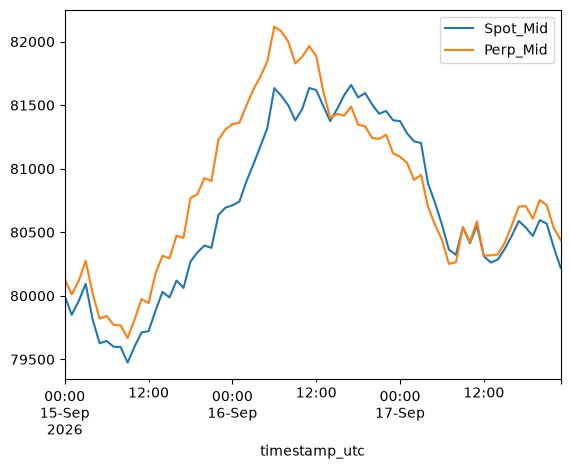

In [20]:
df_btc[['Spot_Mid', 'Perp_Mid']].plot()

<Axes: xlabel='timestamp_utc'>

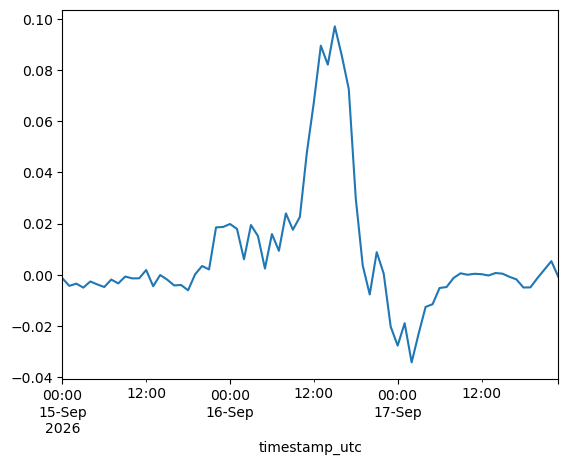

In [20]:
(df_btc['BasisInBPS_USDC'] - df_btc['BasisInBPS_USDT']).plot()

Q3. Suppose you enter the position at the first timestamp and ignore transaction costs/funding. Calculate each hour's:

$$ PnL_{spot},\qquad PnL_{perp},\qquad PnL_{combined}. $$

Does the large movement in BTC/ETH mostly cancel as expected?

In [26]:
df_btc.head()

,product,spot_symbol,perp_symbol,spot_quote_ccy,perp_quote_ccy,spot_qty,perp_qty,spot_bid,spot_ask,perp_bid,...,perp_volume_usd,open_interest_usd,Spot_Mid,Perp_Mid,Spot_Mid_USDT_Terms,Perp_Mid_USDC_Terms,USDT_Basis,USDC_Basis,BasisInBPS_USDT,BasisInBPS_USDC
timestamp_utc,,,,,,,,,,,,,,,,,,,,,
2026-09-15 00:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79996.80,80003.20,80125.26,...,2.109624e+08,1.791965e+09,80000.000,80131.675,80007.200000,80124.463798,124.475000,124.463798,15.546581,15.545182
2026-09-15 01:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79843.37,79857.39,80004.49,...,1.224543e+08,1.796887e+09,79850.380,80010.790,79870.342595,79990.792302,140.447405,140.412302,17.571172,17.566780
2026-09-15 02:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79945.97,79970.67,80112.17,...,2.960957e+08,1.797561e+09,79958.320,80116.675,79974.071789,80100.895124,142.603211,142.575124,17.817050,17.813541
2026-09-15 03:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,80085.01,80102.60,80269.65,...,1.812772e+08,1.804674e+09,80093.805,80274.905,80114.068733,80254.600586,160.836267,160.795586,20.058310,20.053237
2026-09-15 04:00:00+00:00,BTC,BTC-USDC,BTC-USDT-PERP,USDC,USDT,1.0,-1.0,79806.04,79819.99,80015.51,...,1.854489e+08,1.824991e+09,79813.015,80017.510,79821.714619,80008.789042,195.795381,195.774042,24.500374,24.497704


In [25]:
df_btc[['funding_rate_8h', 'funding_event']]

,funding_rate_8h,funding_event
timestamp_utc,,
2026-09-15 00:00:00+00:00,0.000042,0
2026-09-15 01:00:00+00:00,0.000051,0
2026-09-15 02:00:00+00:00,0.000039,0
2026-09-15 03:00:00+00:00,0.000038,0
2026-09-15 04:00:00+00:00,0.000046,0
...,...,...
2026-09-17 19:00:00+00:00,0.000039,0
2026-09-17 20:00:00+00:00,0.000033,0
2026-09-17 21:00:00+00:00,0.000038,0


Q4. For BTC specifically, decompose the spot P&L into BTC-price movement and USDC/USDT movement. Can the strategy lose money even if the BTC delta is very close to zero?

Q5. Add funding. At every row where funding_event == 1, calculate the payment to the short using approximately

$$ \text{Funding PnL} = |q_{perp}|\,P_{mark}\,f_t. $$

Create a cumulative funding-P&L column.







6. Now calculate:

$$ \text{Total PnL} = PnL_{spot} + PnL_{perp} + PnL_{funding}. $$

Which contributes more over the sample: basis movement or funding income?

7. Find an interval where funding is strongly positive but the overall strategy still loses money. Explain exactly how this can happen.
8. Instead of using midpoint prices, pretend you actually execute. To establish a long-spot/short-perp trade, which side of each book do you hit? Do the reverse when closing. Recalculate P&L using executable prices and measure the transaction-cost drag.
9. Compare BTC with ETH. Which is easier to hedge and account for? Quantify how much additional variation the USDC/USDT leg introduces into BTC.
Calculate
$$ \text{Basis}_{bps} = 10,000 \frac{P_{perp}-P_{spot}^{converted}} {P_{spot}^{converted}}. $$

Then investigate whether high basis tends to coincide with high funding in this toy sample.

11. Compare open_interest_usd with funding and basis. During periods where OI rises sharply, what happens to basis and funding? Come up with an economic explanation rather than just reporting correlation.
12. Create forward variables such as next-1h, next-4h and next-8h spot returns and basis changes. Ask whether today's funding rate has any apparent relationship with future price movement versus merely reflecting the current perp premium.
13. Pretend you're deciding whether to enter a cash-and-carry trade. Construct your own rule such as:
$$ \text{enter if basis} > X\text{ bps and funding}>Y. $$

Backtest it on both products and calculate total P&L after execution spread.

14. Finally, build a P&L attribution table:
$$ \boxed{ \text{Total PnL} = \text{spot} + \text{perp} + \text{funding} + \text{stablecoin effect} - \text{execution costs} } $$

and explain which risk you're actually being paid to take in each product.